# Notes
### EDA
- 14417 cihaz veri göndermiş(MNSI)
- LAT (+90 -90 arası olmalı) ve LON (+180 -180 arası olmalı)
- LAT ve LON değerleri her ne kadar üst maddedeki sınırlara uysada modelimizin kafasını karıştırabilecek outlier değerler bulunuyor
- SOG verisinde aşırı uç değerler vardır. Buda olası bir sensör arızası yada hata durumunu işaret ediyor bu veriler temizlenmeli. Ayrıca verinin yarısından fazlası 0'dan oluşmaktadır buda gemilerin hareket halinde olmadığını gösterir.Çarpışma risk analizi yaptığımız için bu gemiler verisetinden çıkarılmalıdır.
- COG verisi gayet temiz gözüküyor. yalnız bu veri açı değerini ifade ettiğinden modelin doğru bir çıkarım yapabilmesi için sinus ve kosinus dönüşümü yapmak mantıklı olacaktır
- Heading veriside COG gibi açısal bir değerdir fakat bu veride 4 milyona yakın 511 değeri vardır. 511 aslında bir açı değeri değil bir hata kodudur.
- Status, VesselType, Cargo asıl olarak encode edilmiş kategorik değerlerdir.
- Length ve Width verilerinde aykırı üst değerler var gibi durmasına karşın gerçek hayattaki çok büyük gemileri ifade ederler
- Draft verisinde negatif değerler sensör hatasıdır geminin su altında kalan kısmı negatif olamaz. boxplottaki üst değerlerse gerçek hayattaki büyük gemilerdir aykırı değer olarak değerlendirilemez
### Outlier
- Koordinat verilerinin LAT ve LON olması gereken aralıkta olup olmadığı kontrol edilmiştir.
- SOG verisi 0 ve 80 knot arasına sabitlenmiştir. 0 olanlar hareketsizliği belirttiği için kaldırılmıştır. Bu filtreleme sonrası elimizdeki 7 milyondan fazla verinin büyük kısmı kaybedilsede yine elimizde 2.6 milyondan fazla veri kalmıştır. 
- COG verisi 0-360 derece arasına sabitlendi.
- Heading Verisindeki 511 değerleri hatayı ifade ettiği için silinip yerine COG değerleriyle doldurulmuştur.bu iki değer akıntı rüzgar gibi etkenlerin olmadığı yerde aynı olmalıdır.rüzgar ve akıntının olmadığı varsayılarak doldurma işlemi gerçekleştirilmiştir.Aynı zamanda 360'dan büyük değerler kaldırılmıştır
- Draft değerinin 0'dan küçük olması engellenmiştir.
- Length ve Width değerlerindeki 0'lara boş değer atanmıştır. 5 metre'den kısa ve 2 metre'den dar olan küçük deniz araçları verisetinden kaldırılmıştır
- Draft ve Cargo verilerinin yüzde 60 - 70'e yakını eksik olduğundan bu metrikler kaldırılmıştır.
### Missing Value
- MNSI numarası ile gemi ismi arasında tutarsızlık olup olmadığı kontrol edilmiştir.
- MNSI, CallSign, IMO, VesselName değerleri aynı şeyi ifade ettiğinden eksik verisi olmayan MNSI değeri tutulmuştur, diğer değerler kaldırılmıştır.
- Length ve Width değerleri MNSI değerine göre gruplayarak doldurulmaya çalışılmıştır fakat bu yöntem işe yaramadığından ve elimizde yeteri kadar veri olduğundan bu değerleri boş olan satırlar silinmiştir.
- VesselType değeri yine MNSI değerine göre gruplayarak doldurulmaya çalışılmıştır fakat bu yöntem bu değer içinde geçersizdir.Modele çok fazla katkısının olmayacağını düşündüğüm için Status ve VesselType değerlerini kaldırdım.
- Bu işlemler sonucunda veri 1.6 milyona kadar düşmüştür
### Feature Engineering
- LAT ve LON verilerine uyguladığımız yuvarlama işlemiyle bir bakıma denizi parsellere bölmüş olduk bu parseler gemileri eşleştirirken işlemci gücünü korumamızı sağlayacak eğer bunu uygulamasaydık 1.6 milyon veriyi birbiri ile ikili eşleştirirken işlemci gücü ve ram bakımından sorun yaşayacaktık ızgara sayesinde ondalıklı basamağın ilk ikisini alarak denizi yaklaşık 1 km karelik alanlara bölmüş olduk.LatGrid ve LonGrid değerlerini oluşturduk.
- Gemilerin AIS cihazları sinyalleri sabit bir zamanda değil rastgele bir zamanda gönderir bu yüzden saat verisini 5 dakika kadar yuvarlayarak TimeGrid değerini oluşturduk ve ayrıca bu veri içinde yukardaki maddede olduğu gibi zamanı 5 dakikalık periyotlara böldük.Gemileri birbirleri ile eşlerken LatGrid + LonGrid + TimeGrid verilerini kullanarak işimizi kolaylaştıracağız.
- Heading ve COG verilerine sinus ve cosinus dönüşümü yapılmıştır bu sayede makine öğrenmesi modelimiz bu verilerin açısal bir değer olduğunu anlayabilecek.
- Verileri MMSI numarası ve daha sonra BaseDateTime değerine göre sıraladım.
### Encoding
- Zaten kategorik veriler sayı şeklinde verildiği için tekrardan encode yapmaya gerek yoktur.
### Scaling 
- Ağaç tabanlı modeller kullanılacağı için ve sonradan oluşturulmuş açısal değerleri kaybetmemek için scaling uygulanmamıştır.

# Import Libs

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

# Import Datasets

In [2]:
#df1 = pd.read_csv("/kaggle/input/datasets/fernandoabril/ais-data-us-coast-2020-january-1-7/data.csv")
#df2 = pd.read_csv("/kaggle/input/datasets/fernandoabril/ais-data-us-coast-2020-january-1-7/data2.csv")
df3 = pd.read_csv("/kaggle/input/datasets/fernandoabril/ais-data-us-coast-2020-january-1-7/data3.csv")

In [3]:
#df1.info()

In [4]:
#df2.info()

In [5]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7118203 entries, 0 to 7118202
Data columns (total 17 columns):
 #   Column            Dtype  
---  ------            -----  
 0   MMSI              int64  
 1   BaseDateTime      object 
 2   LAT               float64
 3   LON               float64
 4   SOG               float64
 5   COG               float64
 6   Heading           float64
 7   VesselName        object 
 8   IMO               object 
 9   CallSign          object 
 10  VesselType        float64
 11  Status            float64
 12  Length            float64
 13  Width             float64
 14  Draft             float64
 15  Cargo             float64
 16  TransceiverClass  object 
dtypes: float64(11), int64(1), object(5)
memory usage: 923.2+ MB


# EDA

In [6]:
df3.head()

,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass
0,368020640,2020-01-03T00:00:00,40.63936,-80.47423,0.0,360.0,511.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,A
1,367683579,2020-01-03T00:00:00,40.12194,-91.51325,0.0,112.2,511.0,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,NaN,A
2,368053210,2020-01-03T00:00:01,57.77782,-152.41355,0.0,307.9,224.0,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,NaN,A
3,316036089,2020-01-03T00:00:00,45.36721,-87.08709,13.3,236.0,235.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,A
4,368051230,2020-01-03T00:00:00,40.73179,-73.97286,0.1,65.7,352.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,A


In [7]:
df3.isna().sum().sort_values(ascending=False)

Draft               5368686
Cargo               5109867
IMO                 4015408
Width               2045392
Status              1561236
CallSign            1274562
Length              1134616
VesselType           721970
VesselName           620976
MMSI                      0
Heading                   0
COG                       0
SOG                       0
LAT                       0
BaseDateTime              0
LON                       0
TransceiverClass          0
dtype: int64

In [8]:
def analyze_col(df,col_name,desc="Feature"):
    print(f"===== {col_name} Analizi =====")
    print(f"{desc} unique değer sayısı:{df[col_name].nunique()}")
    print(f"{desc} unique değer adı ve dağılımı: \n{df[col_name].value_counts()}")
    
analyze_col(df3,"TransceiverClass","Sınıf")
analyze_col(df3,"CallSign")
analyze_col(df3,"IMO")
analyze_col(df3,"VesselName")
analyze_col(df3,"BaseDateTime")
analyze_col(df3,"MMSI")
analyze_col(df3,"Heading")
analyze_col(df3,"Status")
analyze_col(df3,"VesselType")
analyze_col(df3,"Cargo")
analyze_col(df3,"Draft")
analyze_col(df3,"SOG")

===== TransceiverClass Analizi =====
Sınıf unique değer sayısı:2
Sınıf unique değer adı ve dağılımı: 
TransceiverClass
A    5556967
B    1561236
Name: count, dtype: int64
===== CallSign Analizi =====
Feature unique değer sayısı:10909
Feature unique değer adı ve dağılımı: 
CallSign
NONE       1623
WDH8056    1361
APPLY      1346
WDJ7419    1292
AEKH       1287
           ... 
WDH6455       1
9HA3567       1
V7BD3         1
C6FG2         1
WDC6542       1
Name: count, Length: 10909, dtype: int64
===== IMO Analizi =====
Feature unique değer sayısı:4342
Feature unique değer adı ve dağılımı: 
IMO
IMO0000000    617783
IMO0000001      2473
IMO8025680      1276
IMO7413218      1274
IMO8964537      1226
               ...  
IMO9581954         1
IMO8853049         1
IMO9362190         1
IMO9645774         1
IMO9302970         1
Name: count, Length: 4342, dtype: int64
===== VesselName Analizi =====
Feature unique değer sayısı:11965
Feature unique değer adı ve dağılımı: 
VesselName
FREEDOM        

In [9]:
pd.set_option("display.float_format", lambda x: "%.7f" % x)
df3.describe()

,MMSI,LAT,LON,SOG,COG,Heading,VesselType,Status,Length,Width,Draft,Cargo
count,7118203.0000000,7118203.0000000,7118203.0000000,7118203.0000000,7118203.0000000,7118203.0000000,6396233.0000000,5556967.0000000,5983587.0000000,5072811.0000000,1749517.0000000,2008336.0000000
mean,366933816.5335280,35.1574073,-95.7173119,2.0246082,209.3910897,366.8324327,43.6983260,4.2032161,47.7301054,11.0693842,6.1308064,48.0826535
std,57609345.6498181,8.4002093,22.2632749,5.9495905,111.0406307,177.0777331,19.7712119,5.7127880,63.9444490,9.0854465,4.2211707,22.3653420
min,0.0000000,7.0865500,-178.3057900,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,-12.8000000,0.0000000
25%,366904380.0000000,29.6137100,-117.1658800,0.0000000,121.3000000,214.0000000,31.0000000,0.0000000,18.0000000,6.0000000,3.2000000,31.0000000
50%,367386890.0000000,32.6314800,-90.3992000,0.0000000,229.2000000,511.0000000,31.0000000,0.0000000,24.0000000,8.0000000,4.5000000,52.0000000
75%,367705130.0000000,40.6407000,-80.8404750,0.4000000,301.4000000,511.0000000,60.0000000,7.0000000,39.0000000,12.0000000,8.9000000,60.0000000
max,1073709206.0000000,70.4900300,144.9452400,102.3000000,382.6000000,511.0000000,99.0000000,15.0000000,367.0000000,126.0000000,24.1000000,132.0000000


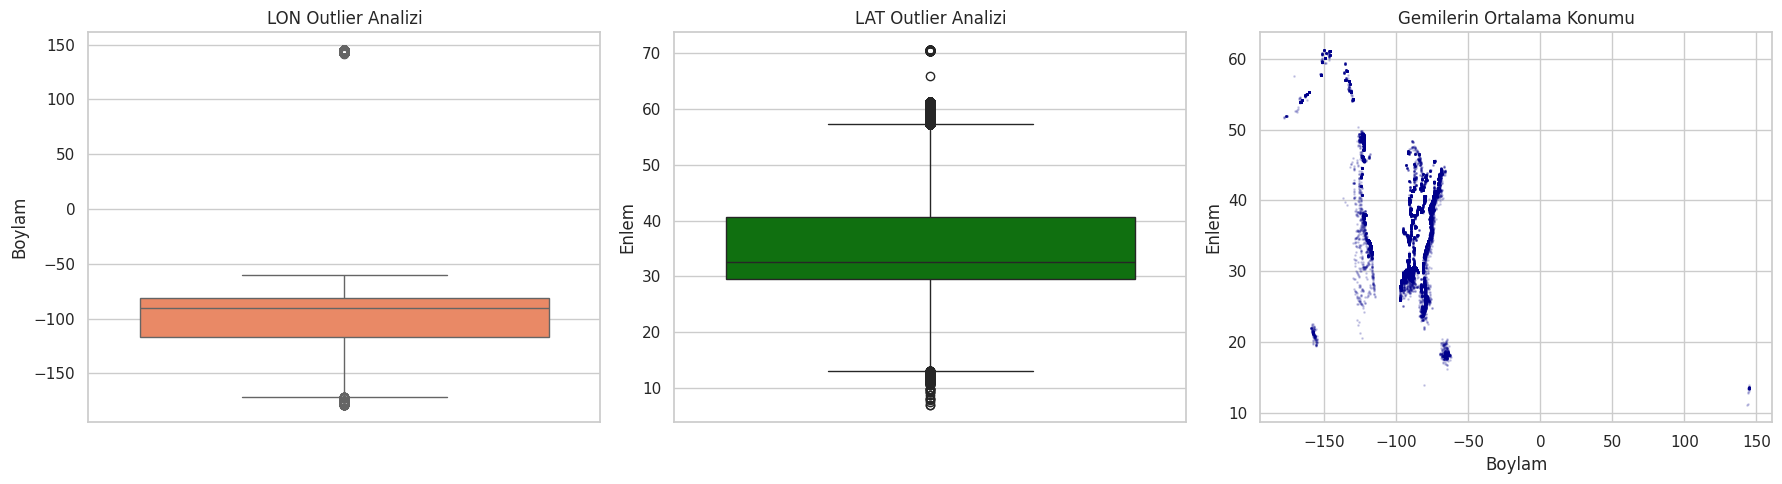

In [10]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


sns.boxplot(y=df3["LON"], color="coral", ax=axes[0])
axes[0].set_title("LON Outlier Analizi")
axes[0].set_ylabel("Boylam")

sns.boxplot(y=df3["LAT"], color="green", ax=axes[1])
axes[1].set_title("LAT Outlier Analizi")
axes[1].set_ylabel("Enlem")

sample_df = df3.sample(n=min(50000, len(df3)), random_state=42)
axes[2].scatter(sample_df["LON"], sample_df["LAT"], alpha=0.15, s=1, color="darkblue")
axes[2].set_title("Gemilerin Ortalama Konumu")
axes[2].set_xlabel("Boylam")
axes[2].set_ylabel("Enlem")

plt.tight_layout()
plt.show()

In [11]:
null_island_df = df3[(df3["LAT"] == 0) & (df3["LON"] == 0)]
len(null_island_df)

0

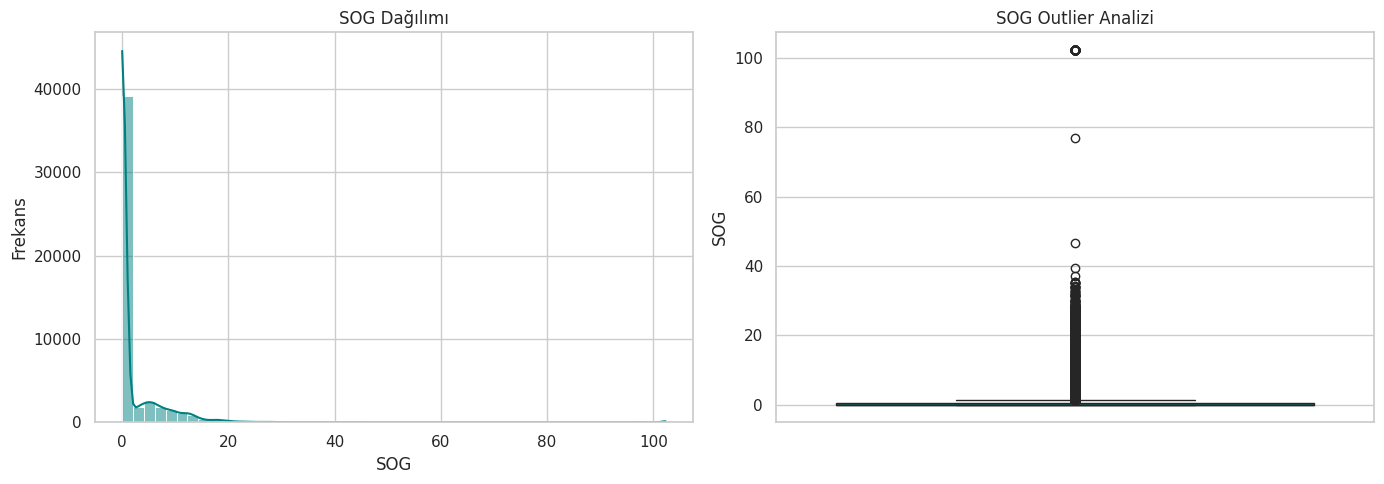

In [12]:
def plot_dist_and_outliers(df, col_name, bins=50, palette="teal"):
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    data = data = df[col_name].dropna().sample(n=50000, random_state=42)

    sns.histplot(data, kde=True, bins=bins, color=palette, ax=axes[0])
    axes[0].set_title(f"{col_name} Dağılımı")
    axes[0].set_xlabel(col_name)
    axes[0].set_ylabel("Frekans")

    sns.boxplot(y=data, color=palette, ax=axes[1])
    axes[1].set_title(f"{col_name} Outlier Analizi")
    axes[1].set_ylabel(col_name)

    plt.tight_layout()
    plt.show()
plot_dist_and_outliers(df3, "SOG")

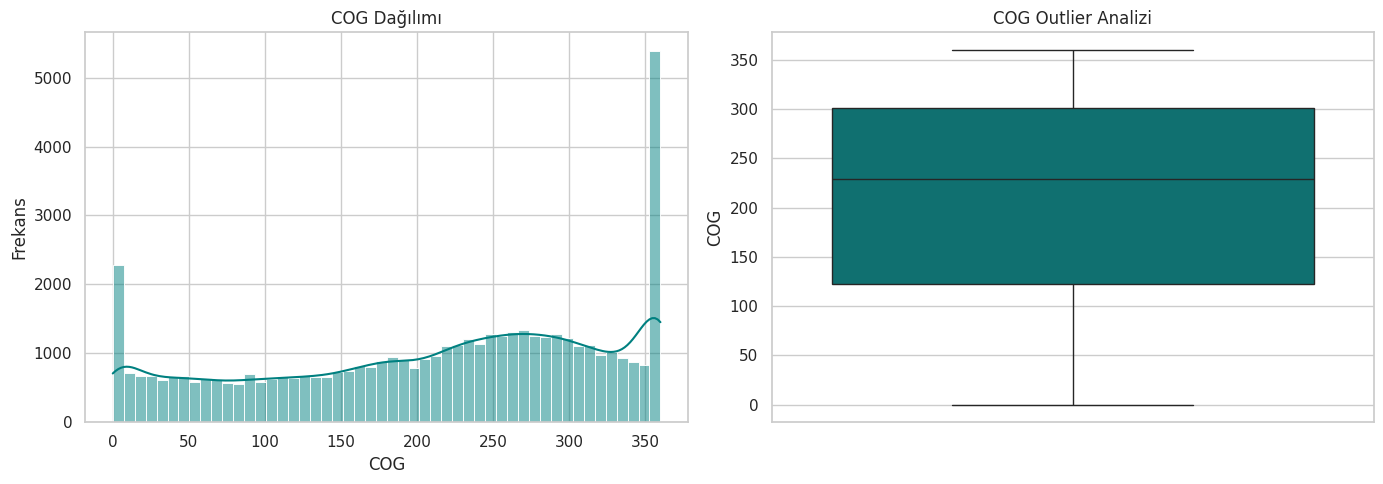

In [13]:
plot_dist_and_outliers(df3, "COG")

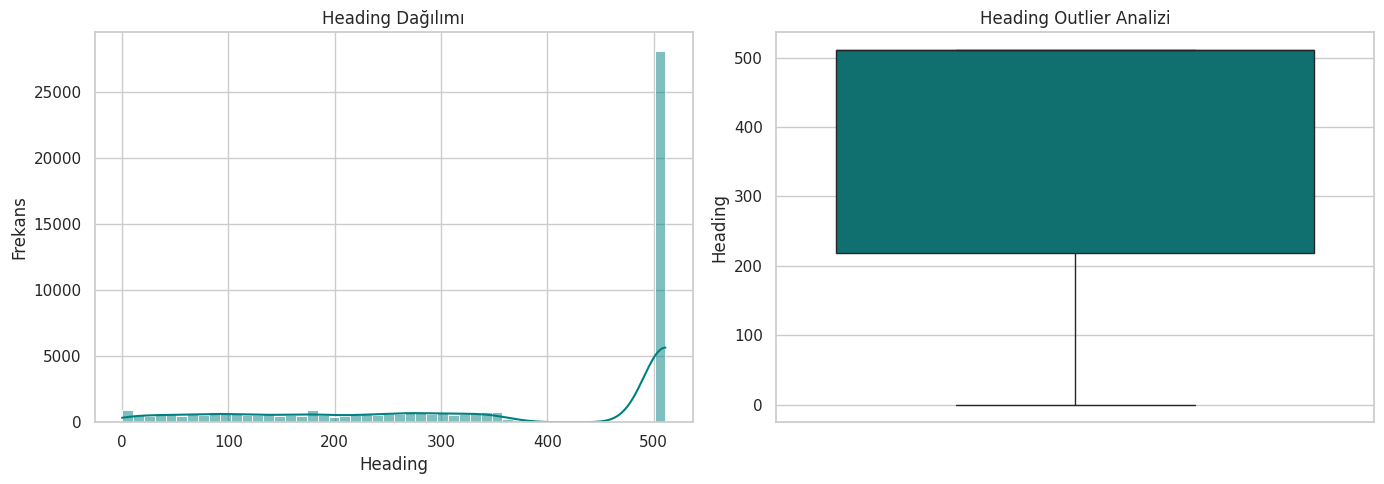

In [14]:
plot_dist_and_outliers(df3, "Heading")

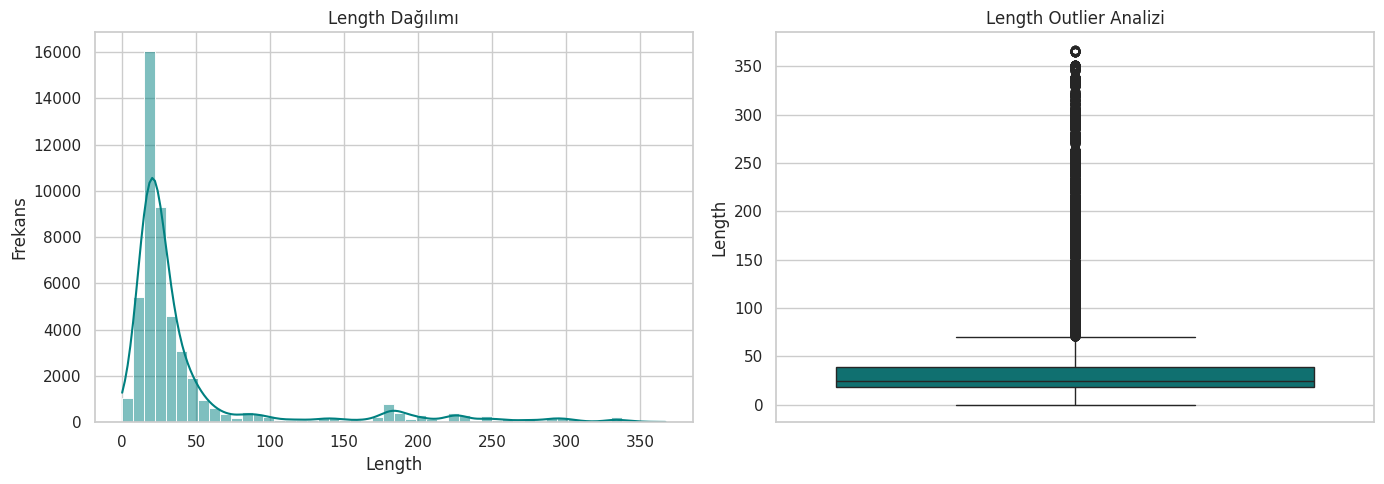

In [15]:
plot_dist_and_outliers(df3, "Length")

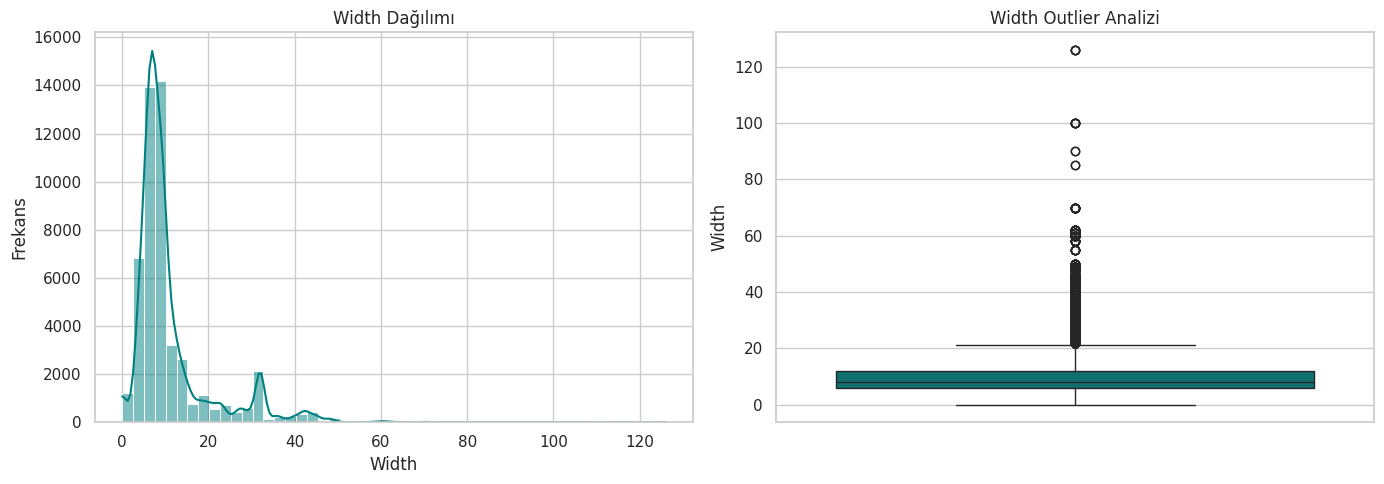

In [16]:
plot_dist_and_outliers(df3, "Width")

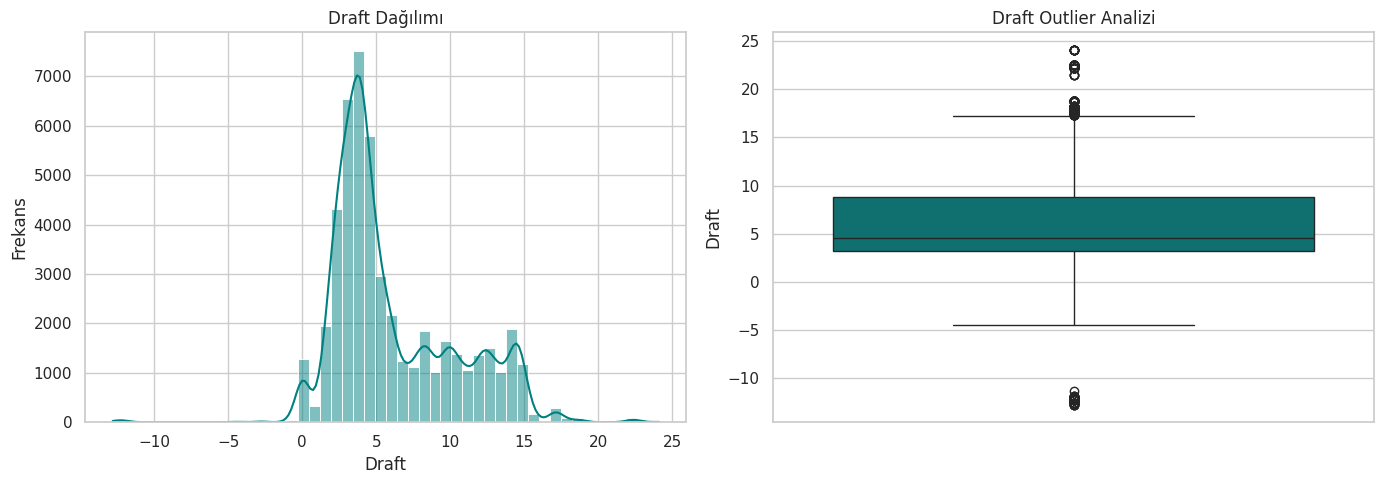

In [17]:
plot_dist_and_outliers(df3, "Draft")

# Outlier

In [18]:
df_copy = df3.copy()

print(f"Filtreleme Öncesi Uzunluk:{len(df_copy)}")

df_copy = df_copy[(df_copy["LAT"] >= -90) & (df_copy["LAT"] <= 90) & 
                  (df_copy["LON"] >= -180) & (df_copy["LON"] <= 180)]

print(f"Filtreleme Sonrası Uzunluk:{len(df_copy)}")
df3 = df_copy

Filtreleme Öncesi Uzunluk:7118203
Filtreleme Sonrası Uzunluk:7118203


In [19]:
df_copy = df3.copy()

print(f"Filtreleme Öncesi Uzunluk:{len(df_copy)}")

df_copy = df_copy[(df_copy["SOG"] > 0) & (df_copy["SOG"] <= 80)]

print(f"Filtreleme Sonrası Uzunluk:{len(df_copy)}")

df3 = df_copy

df3.describe()

Filtreleme Öncesi Uzunluk:7118203
Filtreleme Sonrası Uzunluk:2654697


,MMSI,LAT,LON,SOG,COG,Heading,VesselType,Status,Length,Width,Draft,Cargo
count,2654697.0000000,2654697.0000000,2654697.0000000,2654697.0000000,2654697.0000000,2654697.0000000,2364224.0000000,2213881.0000000,2242437.0000000,1947006.0000000,798956.0000000,828334.0000000
mean,371453308.2900308,34.2076996,-93.4809417,4.9190114,189.9213988,332.4093650,45.7428370,3.3910888,63.2234462,13.2236162,7.1795703,50.5178249
std,70397191.3264660,7.9966683,22.1333676,5.4382212,105.3439587,181.2837077,20.7121761,5.5027882,79.5938274,10.7148067,4.5585270,22.7463019
min,11.0000000,7.0865500,-178.3057900,0.1000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,-12.8000000,0.0000000
25%,366904000.0000000,29.3516100,-95.3265900,0.2000000,99.7000000,165.0000000,31.0000000,0.0000000,19.0000000,7.0000000,3.6000000,31.0000000
50%,367390470.0000000,31.2239800,-90.2289800,3.6000000,192.7000000,334.0000000,31.0000000,0.0000000,26.0000000,9.0000000,5.8000000,52.0000000
75%,367730420.0000000,39.8592900,-80.1331600,8.0000000,280.3000000,511.0000000,60.0000000,5.0000000,51.0000000,14.0000000,10.8000000,70.0000000
max,1073709206.0000000,70.4900000,144.9452400,78.9000000,382.6000000,511.0000000,99.0000000,15.0000000,367.0000000,126.0000000,24.1000000,132.0000000


In [20]:
df_copy = df3.copy()

print(f"Filtreleme Öncesi Uzunluk:{len(df_copy)}")

df_copy = df_copy[(df_copy["COG"] >= 0) & (df_copy["COG"] <= 360)]

print(f"Filtreleme Sonrası Uzunluk:{len(df_copy)}")

df3 = df_copy

Filtreleme Öncesi Uzunluk:2654697
Filtreleme Sonrası Uzunluk:2654696


In [21]:
df_copy = df3.copy()

print(f"Filtreleme Öncesi Uzunluk:{len(df_copy)}")

df_copy["Heading"] = df_copy["Heading"].replace(511, np.nan)
df_copy["Heading"] = df_copy["Heading"].fillna(df_copy["COG"])
df_copy = df_copy[(df_copy["Heading"] >= 0) & (df_copy["Heading"] <= 360)]

print(f"Filtreleme Sonrası Uzunluk:{len(df3)}")

df3 = df_copy

Filtreleme Öncesi Uzunluk:2654696
Filtreleme Sonrası Uzunluk:2654696


In [22]:
df_copy = df3.copy()

print(f"Filtreleme Öncesi Uzunluk:{len(df_copy)}")

df_copy = df_copy[(df_copy["Draft"] > 0) & (df_copy["Draft"] <= 30) | (df_copy["Draft"].isna())]

print(f"Filtreleme Sonrası Uzunluk:{len(df_copy)}")

df3 = df_copy

Filtreleme Öncesi Uzunluk:2654695
Filtreleme Sonrası Uzunluk:2633186


In [23]:
df3["Length"] = df3["Length"].replace(0, np.nan)
df3["Width"] = df3["Width"].replace(0, np.nan)

In [24]:
kisa_gemi_sayisi = len(df3[df3["Length"] < 5])
dar_gemi_sayisi = len(df3[df3["Width"] < 2])

print(f"5 metreden kısa gemi sayısı:{kisa_gemi_sayisi:,}")
print(f"2 metreden dar olan gemi sayısı:{dar_gemi_sayisi:,}")

5 metreden kısa gemi sayısı:407
2 metreden dar olan gemi sayısı:123


In [25]:
df_copy = df3.copy()

print(f"Filtreleme Öncesi Uzunluk:{len(df_copy)}")

df_copy = df_copy[
    ((df_copy["Length"] >= 5) | (df_copy['Length'].isna())) & 
    ((df_copy["Width"] >= 2) | (df_copy['Width'].isna()))
]

print(f"Filtreleme Sonrası Uzunluk:{len(df_copy)}")

df3 = df_copy

Filtreleme Öncesi Uzunluk:2633186
Filtreleme Sonrası Uzunluk:2632733


In [26]:
df3.describe()

,MMSI,LAT,LON,SOG,COG,Heading,VesselType,Status,Length,Width,Draft,Cargo
count,2632733.0000000,2632733.0000000,2632733.0000000,2632733.0000000,2632733.0000000,2632733.0000000,2342261.0000000,2192561.0000000,2196340.0000000,1899219.0000000,777447.0000000,806825.0000000
mean,371179782.4548706,34.2258409,-93.5287538,4.9334426,189.8818766,187.0860958,45.8165969,3.3662457,64.0765196,13.4304596,7.4112535,50.8887702
std,68961548.1113414,8.0089679,22.1897777,5.4426737,105.3855841,105.7208239,20.5950682,5.4790834,79.6588223,10.6131081,4.3626043,22.3888750
min,11.0000000,7.0865500,-178.3057900,0.1000000,0.0000000,0.0000000,0.0000000,0.0000000,5.0000000,2.0000000,0.3000000,0.0000000
25%,366902570.0000000,29.3520500,-95.3547200,0.2000000,99.5000000,95.4000000,31.0000000,0.0000000,19.0000000,7.0000000,3.7000000,31.0000000
50%,367389530.0000000,31.2699500,-90.2316700,3.6000000,192.5000000,187.0000000,31.0000000,0.0000000,27.0000000,9.0000000,6.0000000,52.0000000
75%,367728570.0000000,39.8747500,-80.1343200,8.0000000,280.4000000,278.9000000,60.0000000,5.0000000,53.0000000,15.0000000,11.0000000,70.0000000
max,1056913653.0000000,70.4900000,144.9452400,78.9000000,360.0000000,360.0000000,99.0000000,15.0000000,367.0000000,100.0000000,24.1000000,132.0000000


# Missing Value

In [27]:
df3.isna().sum()

MMSI                      0
BaseDateTime              0
LAT                       0
LON                       0
SOG                       0
COG                       0
Heading                   0
VesselName           259592
IMO                 1363072
CallSign             423161
VesselType           290472
Status               440172
Length               436393
Width                733514
Draft               1855286
Cargo               1825908
TransceiverClass          0
dtype: int64

In [28]:
len(df3)

2632733

In [29]:
mmsi_vessel_counts = df3.groupby("MMSI")["VesselName"].nunique()

problematic_mmsis = mmsi_vessel_counts[mmsi_vessel_counts > 1]

print(f"MNSI numarasında hata olanlar:{len(problematic_mmsis)}")

MNSI numarasında hata olanlar:0


In [30]:
columns_to_drop = ["CallSign", "IMO", "VesselName"]
df3 = df3.drop(columns=[col for col in columns_to_drop if col in df3.columns])

print(df3.columns)

Index(['MMSI', 'BaseDateTime', 'LAT', 'LON', 'SOG', 'COG', 'Heading',
       'VesselType', 'Status', 'Length', 'Width', 'Draft', 'Cargo',
       'TransceiverClass'],
      dtype='object')


In [31]:
cols_to_fill = ["Length", "Width", "Draft", "VesselType"]

for col in cols_to_fill:
    df3[col] = df3.groupby("MMSI")[col].transform(lambda x: x.ffill().bfill())
    
print(df3[["Length", "Width", "Draft", "VesselType"]].isna().sum())

Length         436393
Width          733514
Draft         1855286
VesselType     290472
dtype: int64


In [32]:
df3 = df3.drop(columns=["Draft", "Cargo"])

df3.isna().sum()

MMSI                     0
BaseDateTime             0
LAT                      0
LON                      0
SOG                      0
COG                      0
Heading                  0
VesselType          290472
Status              440172
Length              436393
Width               733514
TransceiverClass         0
dtype: int64

In [33]:
df3 = df3.dropna(subset=["Length", "Width"])
print(len(df3))
df3.isna().sum()

1898752


MMSI                     0
BaseDateTime             0
LAT                      0
LON                      0
SOG                      0
COG                      0
Heading                  0
VesselType            7862
Status              285300
Length                   0
Width                    0
TransceiverClass         0
dtype: int64

In [34]:
df3 = df3.dropna(subset=["Status","VesselType"])
print(len(df3))
df3.isna().sum()

1605590


MMSI                0
BaseDateTime        0
LAT                 0
LON                 0
SOG                 0
COG                 0
Heading             0
VesselType          0
Status              0
Length              0
Width               0
TransceiverClass    0
dtype: int64

In [35]:
df3.describe()

,MMSI,LAT,LON,SOG,COG,Heading,VesselType,Status,Length,Width
count,1605590.0000000,1605590.0000000,1605590.0000000,1605590.0000000,1605590.0000000,1605590.0000000,1605590.0000000,1605590.0000000,1605590.0000000,1605590.0000000
mean,371647942.2614235,34.5089154,-93.1540086,5.2807514,187.8352607,184.7307275,48.4362091,2.9678872,76.3253502,14.7999527
std,67159987.7556721,7.7119671,21.2147191,5.4303826,103.4595832,104.2924847,21.8033810,5.2243190,85.8516787,10.9525102
min,12345678.0000000,7.0865500,-178.3057900,0.1000000,0.0000000,0.0000000,0.0000000,0.0000000,5.0000000,3.0000000
25%,366920310.0000000,29.6023625,-95.0917875,0.2000000,99.4000000,94.1000000,31.0000000,0.0000000,22.0000000,7.0000000
50%,367155310.0000000,31.4688800,-90.2994200,4.2000000,190.8000000,184.6000000,31.0000000,0.0000000,33.0000000,10.0000000
75%,367580880.0000000,39.9761000,-80.3313625,8.7000000,276.5000000,275.0000000,70.0000000,5.0000000,94.0000000,18.0000000
max,896876500.0000000,70.4900000,144.9452400,43.2000000,360.0000000,360.0000000,99.0000000,15.0000000,367.0000000,100.0000000


In [36]:
clean_df = df3.copy()
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1605590 entries, 18 to 7118191
Data columns (total 12 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   MMSI              1605590 non-null  int64  
 1   BaseDateTime      1605590 non-null  object 
 2   LAT               1605590 non-null  float64
 3   LON               1605590 non-null  float64
 4   SOG               1605590 non-null  float64
 5   COG               1605590 non-null  float64
 6   Heading           1605590 non-null  float64
 7   VesselType        1605590 non-null  float64
 8   Status            1605590 non-null  float64
 9   Length            1605590 non-null  float64
 10  Width             1605590 non-null  float64
 11  TransceiverClass  1605590 non-null  object 
dtypes: float64(9), int64(1), object(2)
memory usage: 159.2+ MB


# Feature Engineering

In [37]:
clean_df["BaseDateTime"] = pd.to_datetime(clean_df["BaseDateTime"])
clean_df["BaseDateTime"].isna().sum()

np.int64(0)

In [38]:
clean_df["TimeGrid"] = clean_df["BaseDateTime"].dt.round("5min")
print(clean_df[["BaseDateTime", "TimeGrid"]].head())

           BaseDateTime   TimeGrid
18  2020-01-03 00:00:04 2020-01-03
23  2020-01-03 00:00:05 2020-01-03
48  2020-01-03 00:00:05 2020-01-03
77  2020-01-03 00:00:05 2020-01-03
102 2020-01-03 00:00:01 2020-01-03


In [39]:
print(clean_df[["BaseDateTime", "TimeGrid"]].iloc[10000:10005])

             BaseDateTime            TimeGrid
40726 2020-01-03 00:07:25 2020-01-03 00:05:00
40729 2020-01-03 00:07:55 2020-01-03 00:10:00
40732 2020-01-03 00:07:14 2020-01-03 00:05:00
40734 2020-01-03 00:07:19 2020-01-03 00:05:00
40737 2020-01-03 00:07:30 2020-01-03 00:10:00


In [40]:
clean_df["LatGrid"] = clean_df["LAT"].round(2)
clean_df["LonGrid"] = clean_df["LON"].round(2)
print(clean_df[["LAT", "LatGrid", "LON", "LonGrid"]].head())

           LAT    LatGrid          LON      LonGrid
18  39.2004600 39.2000000  -76.2616700  -76.2600000
23  47.3262100 47.3300000 -125.3846600 -125.3800000
48  29.4576800 29.4600000  -89.6376900  -89.6400000
77  46.7060700 46.7100000  -84.8440000  -84.8400000
102 39.8403100 39.8400000  -79.9315500  -79.9300000


In [41]:
clean_df["COG_sin"] = np.sin(np.radians(clean_df["COG"]))
clean_df["COG_cos"] = np.cos(np.radians(clean_df["COG"]))

clean_df["Heading_sin"] = np.sin(np.radians(clean_df["Heading"]))
clean_df["Heading_cos"] = np.cos(np.radians(clean_df["Heading"]))

display(clean_df[["COG", "COG_sin", "COG_cos", "Heading", "Heading_sin","Heading_cos"]].head())

,COG,COG_sin,COG_cos,Heading,Heading_sin,Heading_cos
18,221.6000000,-0.6639262,-0.7477981,222.0000000,-0.6691306,-0.7431448
23,356.2000000,-0.0662739,0.9978015,355.0000000,-0.0871557,0.9961947
48,278.0000000,-0.9902681,0.1391731,278.0000000,-0.9902681,0.1391731
77,147.5000000,0.5372996,-0.8433914,149.0000000,0.5150381,-0.8571673
102,276.6000000,-0.9933728,0.1149372,276.6000000,-0.9933728,0.1149372


In [42]:
mmsi_counts = clean_df["MMSI"].value_counts()
single_signal_mmsis = mmsi_counts[mmsi_counts == 1].index
clean_df = clean_df[~clean_df["MMSI"].isin(single_signal_mmsis)]
print(f"Güncel satır sayısı:{len(clean_df)}")

Güncel satır sayısı:1605414


In [43]:
clean_df = clean_df.sort_values(by=["MMSI", "BaseDateTime"])

In [44]:
clean_df["TimeDiff_sec"] = clean_df.groupby("MMSI")["BaseDateTime"].diff().dt.total_seconds()

clean_df["SpeedDiff"] = clean_df.groupby("MMSI")["SOG"].diff()
clean_df["Acceleration"] = clean_df["SpeedDiff"] / clean_df["TimeDiff_sec"]

clean_df["COGDiff"] = clean_df.groupby("MMSI")["COG"].diff()
clean_df["ROT"] = clean_df["COGDiff"] / clean_df["TimeDiff_sec"]

cols_to_zero = ["TimeDiff_sec", "SpeedDiff", "Acceleration", "COGDiff", "ROT"]
clean_df[cols_to_zero] = clean_df[cols_to_zero].fillna(0)

clean_df = clean_df.replace([np.inf, -np.inf], 0)

display(clean_df[["MMSI", "BaseDateTime", "SOG", "Acceleration", "COG", "ROT"]].tail(40))

,MMSI,BaseDateTime,SOG,Acceleration,COG,ROT
6845348,884996350,2020-01-03 22:35:23,4.4000000,0.0227513,265.2000000,0.5629630
6870119,884996350,2020-01-03 22:36:35,1.6000000,-0.0388889,0.7000000,-3.6736111
6665742,884996350,2020-01-03 22:39:08,9.7000000,0.0529412,111.2000000,0.7222222
6865033,884996350,2020-01-03 22:40:28,9.6000000,-0.0012500,123.4000000,0.1525000
6686185,884996350,2020-01-03 22:41:49,7.1000000,-0.0308642,97.9000000,-0.3148148
6902438,884996350,2020-01-03 22:47:14,4.8000000,-0.0070769,313.6000000,0.6636923
6712800,884996350,2020-01-03 22:48:24,4.4000000,-0.0057143,311.7000000,-0.0271429
6912576,884996350,2020-01-03 22:54:51,1.1000000,-0.0085271,302.0000000,-0.0250646
6792818,884996350,2020-01-03 23:05:10,4.1000000,0.0048465,290.5000000,-0.0185784
6796538,884996350,2020-01-03 23:06:20,0.8000000,-0.0471429,314.5000000,0.3428571


In [45]:
pairs_df = clean_df.merge(clean_df, on=["TimeGrid", "LatGrid", "LonGrid"], suffixes=("_1", "_2"))

pairs_df = pairs_df[pairs_df["MMSI_1"] < pairs_df["MMSI_2"]].copy()

print(f"Çarpışma Riski Olan Gemi Çifti Sayısı: {len(pairs_df)}")

display(pairs_df[["MMSI_1", "MMSI_2", "TimeGrid", "LatGrid", "LonGrid"]].head(50))

Çarpışma Riski Olan Gemi Çifti Sayısı: 748767


,MMSI_1,MMSI_2,TimeGrid,LatGrid,LonGrid
1,12345678,367633260,2020-01-03 04:15:00,30.0500000,-90.5400000
2,12345678,367633260,2020-01-03 04:15:00,30.0500000,-90.5400000
3,12345678,367633260,2020-01-03 04:15:00,30.0500000,-90.5400000
5,12345678,366991860,2020-01-03 05:20:00,30.0500000,-90.5400000
6,12345678,366991860,2020-01-03 05:20:00,30.0500000,-90.5400000
7,12345678,366991860,2020-01-03 05:20:00,30.0500000,-90.5400000
9,12345678,366991860,2020-01-03 05:25:00,30.0500000,-90.5400000
10,12345678,366991860,2020-01-03 05:25:00,30.0500000,-90.5400000
11,12345678,367755720,2020-01-03 05:25:00,30.0500000,-90.5400000
14,12345678,357520610,2020-01-03 05:30:00,30.0500000,-90.5400000


In [46]:
dY = (pairs_df["LAT_2"] - pairs_df["LAT_1"]) * 111320
dX = (pairs_df["LON_2"] - pairs_df["LON_1"]) * 111320 * np.cos(np.radians(pairs_df["LAT_1"]))

v1_ms = pairs_df["SOG_1"] * 0.514444
vx1 = v1_ms * np.sin(np.radians(pairs_df["COG_1"]))
vy1 = v1_ms * np.cos(np.radians(pairs_df["COG_1"]))

v2_ms = pairs_df["SOG_2"] * 0.514444
vx2 = v2_ms * np.sin(np.radians(pairs_df["COG_2"]))
vy2 = v2_ms * np.cos(np.radians(pairs_df["COG_2"]))

dVx = vx2 - vx1
dVy = vy2 - vy1
v_rel_sq = dVx**2 + dVy**2

v_rel_sq = np.where(v_rel_sq == 0, 1e-6, v_rel_sq)

pairs_df["TCPA"] = -(dX * dVx + dY * dVy) / v_rel_sq

pairs_df["DCPA"] = np.sqrt((dX + dVx * pairs_df["TCPA"])**2 + (dY + dVy * pairs_df["TCPA"])**2)

display(pairs_df[["MMSI_1", "MMSI_2", "DCPA", "TCPA"]].head(50))

,MMSI_1,MMSI_2,DCPA,TCPA
1,12345678,367633260,470.6551955,501.2839733
2,12345678,367633260,433.3069456,1064.8210889
3,12345678,367633260,58.4888587,2052.0297512
5,12345678,366991860,160.3243310,-19025.1048453
6,12345678,366991860,203.7805128,-5140.6642680
7,12345678,366991860,259.2814254,-1009.8631648
9,12345678,366991860,206.4001407,-7372.3829826
10,12345678,366991860,256.1388409,-1339.9847095
11,12345678,367755720,464.9315445,28.8022887
14,12345678,357520610,317.4781183,-119671.6922489


In [47]:
conditions = [
    (pairs_df["DCPA"] < 500) & (pairs_df["TCPA"] >= 0) & (pairs_df["TCPA"] <= 600),
    (pairs_df["DCPA"] < 2000) & (pairs_df["TCPA"] >= 0) & (pairs_df["TCPA"] <= 1800)
]

choices = [2, 1]

pairs_df["Risk_Level"] = np.select(conditions, choices, default=0)

print("0: Güvenli | 1: Riskli | 2: Çok Riskli")
print(pairs_df["Risk_Level"].value_counts().sort_index())

0: Güvenli | 1: Riskli | 2: Çok Riskli
Risk_Level
0    433764
1     70365
2    244638
Name: count, dtype: int64


In [48]:
pairs_df.columns

Index(['MMSI_1', 'BaseDateTime_1', 'LAT_1', 'LON_1', 'SOG_1', 'COG_1',
       'Heading_1', 'VesselType_1', 'Status_1', 'Length_1', 'Width_1',
       'TransceiverClass_1', 'TimeGrid', 'LatGrid', 'LonGrid', 'COG_sin_1',
       'COG_cos_1', 'Heading_sin_1', 'Heading_cos_1', 'TimeDiff_sec_1',
       'SpeedDiff_1', 'Acceleration_1', 'COGDiff_1', 'ROT_1', 'MMSI_2',
       'BaseDateTime_2', 'LAT_2', 'LON_2', 'SOG_2', 'COG_2', 'Heading_2',
       'VesselType_2', 'Status_2', 'Length_2', 'Width_2', 'TransceiverClass_2',
       'COG_sin_2', 'COG_cos_2', 'Heading_sin_2', 'Heading_cos_2',
       'TimeDiff_sec_2', 'SpeedDiff_2', 'Acceleration_2', 'COGDiff_2', 'ROT_2',
       'TCPA', 'DCPA', 'Risk_Level'],
      dtype='object')

In [49]:
cols_to_drop = [
    "MMSI_1", "MMSI_2", "TimeGrid", "LatGrid", "LonGrid",
    "BaseDateTime_1", "BaseDateTime_2", "LAT_1", "LON_1", "LAT_2", "LON_2",
    "COG_1", "COG_2", "Heading_1", "Heading_2",
    "TimeDiff_sec_1", "TimeDiff_sec_2", "SpeedDiff_1", "SpeedDiff_2", 
    "COGDiff_1", "COGDiff_2", "TransceiverClass_1", "TransceiverClass_2","TCPA", "DCPA"
]
pairs_df = pairs_df.drop(columns=cols_to_drop)

display(pairs_df.head())

,SOG_1,VesselType_1,Status_1,Length_1,Width_1,COG_sin_1,COG_cos_1,Heading_sin_1,Heading_cos_1,Acceleration_1,...,Status_2,Length_2,Width_2,COG_sin_2,COG_cos_2,Heading_sin_2,Heading_cos_2,Acceleration_2,ROT_2,Risk_Level
1,0.1000000,32.0000000,0.0000000,65.0000000,14.0000000,0.7826082,-0.6225146,0.7826082,-0.6225146,0.0000000,...,9.0000000,18.0000000,7.0000000,0.2722802,0.9622180,-0.9816272,0.1908090,-0.0150000,-0.3210000,2
2,0.1000000,32.0000000,0.0000000,65.0000000,14.0000000,0.7826082,-0.6225146,0.7826082,-0.6225146,0.0000000,...,9.0000000,18.0000000,7.0000000,0.2164396,0.9762960,-0.9986295,0.0523360,-0.0055556,-0.0366667,1
3,0.1000000,32.0000000,0.0000000,65.0000000,14.0000000,0.7826082,-0.6225146,0.7826082,-0.6225146,0.0000000,...,9.0000000,18.0000000,7.0000000,-0.8633956,0.5045276,-0.8829476,0.4694716,-0.0011111,3.1977778,0
5,0.1000000,32.0000000,0.0000000,65.0000000,14.0000000,0.2503800,-0.9681476,0.2503800,-0.9681476,0.0000000,...,0.0000000,16.0000000,6.0000000,0.0348995,-0.9993908,-0.9563048,0.2923717,0.0000000,-0.2760000,0
6,0.1000000,32.0000000,0.0000000,65.0000000,14.0000000,0.2503800,-0.9681476,0.2503800,-0.9681476,0.0000000,...,0.0000000,16.0000000,6.0000000,-0.4019478,-0.9156626,-0.9702957,0.2419219,0.0000000,0.1976923,0


In [50]:
pairs_df.columns

Index(['SOG_1', 'VesselType_1', 'Status_1', 'Length_1', 'Width_1', 'COG_sin_1',
       'COG_cos_1', 'Heading_sin_1', 'Heading_cos_1', 'Acceleration_1',
       'ROT_1', 'SOG_2', 'VesselType_2', 'Status_2', 'Length_2', 'Width_2',
       'COG_sin_2', 'COG_cos_2', 'Heading_sin_2', 'Heading_cos_2',
       'Acceleration_2', 'ROT_2', 'Risk_Level'],
      dtype='object')

# Train Test Split

In [51]:
X = pairs_df.drop(columns=["Risk_Level"])
y = pairs_df["Risk_Level"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)